Dataset shape: (1797, 64)
Target classes: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9}


C:\Users\prathamesh\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(



Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.83      0.91        54
           1       0.81      0.64      0.71        55
           2       0.94      0.91      0.92        53
           3       0.85      0.91      0.88        55
           4       1.00      0.89      0.94        54
           5       0.93      0.95      0.94        55
           6       0.96      0.94      0.95        54
           7       0.89      1.00      0.94        54
           8       0.66      0.90      0.76        52
           9       0.81      0.80      0.80        54

    accuracy                           0.88       540
   macro avg       0.89      0.88      0.88       540
weighted avg       0.89      0.88      0.88       540

Accuracy: 0.8759259259259259


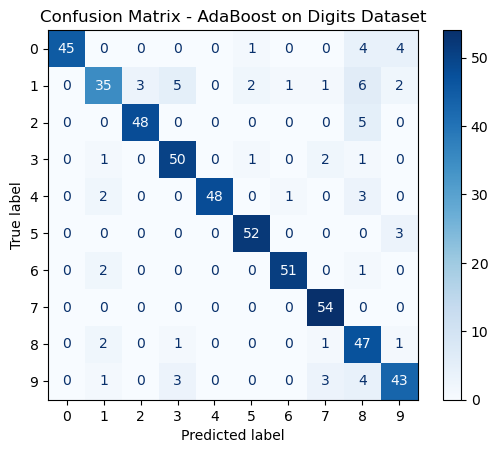

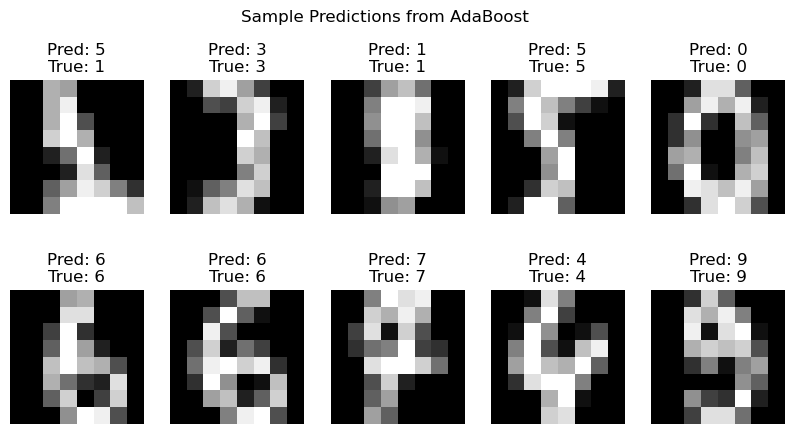

In [9]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay

# 1. Load dataset (images)
digits = load_digits()
X, y = digits.data, digits.target   # X: flattened images (64 pixels), y: digit labels

print("Dataset shape:", X.shape)   # (1797, 64)
print("Target classes:", set(y))

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 3. Create AdaBoost classifier with Decision Trees as weak learners
weak_learner = DecisionTreeClassifier(max_depth=2)  # shallow tree
adaboost_clf = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=50,         # number of weak learners
    learning_rate=1.0,
    algorithm="SAMME",     # real boosting (probability-based)
    random_state=42
)

# 4. Train AdaBoost
adaboost_clf.fit(X_train, y_train)

# 5. Predictions
y_pred = adaboost_clf.predict(X_test)

# 6. Evaluation
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

# 7. Confusion Matrix
ConfusionMatrixDisplay.from_estimator(adaboost_clf, X_test, y_test, cmap="Blues")
plt.title("Confusion Matrix - AdaBoost on Digits Dataset")
plt.show()

# 8. Visualizing some images and predictions
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray")
    ax.set_title(f"Pred: {y_pred[i]}\nTrue: {y_test[i]}")
    ax.axis("off")
plt.suptitle("Sample Predictions from AdaBoost")
plt.show()
